# DA2402 Project: Earthquake Deaths, Magnitude, and Income
Team Members: Shashank DA25B015, Varshith DA25B010

Date: 5th November, 2026

Github Repo: https://github.com/SilvernOak/DA2402_Project_Earthquakes

## 1. Introduction
Earthquakes are a purely geological hazard, but the resulting human disaster is heavily influenced by socio-economic factors. 

The core question this project seeks to answer is: After allowing for physical constraints (magnitude and depth), how much does a country's income explain earthquake deaths?

By integrating seismological data with economic development indicators, this report evaluates whether wealth acts as a protective shield against geological hazards, quantifying exactly how much a tenfold increase in GDP per capita reduces expected mortality.

## 2. Data Collection & Ethics

Data were collected from four independent sources covering **2000–2025**. The original downloaded data were preserved without modification in the `raw/` directory. Intermediate processing outputs, scraping logs, and access-policy evidence were retained separately for reproducibility.

### 1. USGS ComCat API - Geological Parameters

- **Collection:** Earthquake records were retrieved through the USGS FDSN Event API, covering events of magnitude 6.0 and above between 2000 and 2025.
- **Terms and licence:** USGS earthquake data are in the U.S. Public Domain.
- **Access considerations:** API requests were rate-limited, with no concurrent request bursts, to avoid unnecessarily burdening the service.

### 2. NOAA NCEI Significant Earthquake Database - Fatalities

- **Collection:** Historical earthquake and fatality records were retrieved through the NOAA NCEI HazEL API.
- **Cross-source matching:** NOAA records were matched to USGS events using a temporal tolerance of **±1 day** and a spatial tolerance of **150 km**.
- **Terms and licence:** NOAA NCEI data are generally in the U.S. Public Domain as U.S. Government Works.
- **Robots.txt review:** The NOAA robots.txt file returned HTTP status 200. It specifies a crawl-delay of **60 seconds**. Requests were handled conservatively, and a local cache was implemented to avoid repeatedly contacting the server when rerunning the notebook.


### 3. Wikipedia - Alternative Fatalities / Missing Data Augmentation
* **Collection:** Scraped from MediaWiki 'List of earthquakes in YYYY' articles. 
* **Ethics & `robots.txt`:** Checked `robots.txt` before scraping to ensure compliance with server loads and disallowed directories.
  * *Quote from `robots_wikipedia.txt`:* "Please note: There are a lot of pages on this site, and there are some misbehaved spiders out there that go _way_ too fast. If you're irresponsible, your access to the site may be blocked."
  * *Global Directive:* `User-agent: *` is permitted to crawl standard article paths, provided rate limits are respected.
  * **Licence:** Creative Commons CC BY-SA 4.0.

### 4. World Bank WDI API - Socio-Economic Exposure

* **Collection:** Fetched via API for indicators including GDP per capita (PPP, constant 2021 $) and population density. 
* **Ethics & `robots.txt`:** Checked `robots.txt` before executing queries. The API endpoint (`api.worldbank.org/robots.txt`) returned a 404. However, the main domain's `robots.txt` was verified.
  * *Quote from `robots_worldbank_nonapi_2026-10-22.txt`:* "User-agent: * Allow: /" (Followed by specific disallowed system paths like `/apps/` and `/conf/`).
  * **Licence:** Creative Commons CC BY 4.0. 

### Ethical and Reproducibility Considerations

Across the four sources, the collection process followed the relevant access policies and usage conditions. API requests and web requests were kept conservative, and local caching was used where appropriate to reduce repeated requests.

Original source files, robots.txt responses, and collection logs were retained to support traceability and reproducibility. Robots.txt compliance was treated as an access-policy check, separate from the applicable API terms, website terms, and data licences.

## 3. Data Storage Strategy
A strict three-tier storage architecture (raw/, interim/, clean/) was maintained to ensure immutability of the source data. File formats were chosen strategically based on their structural advantages:
- Raw Data: Preserved in native formats (JSON for APIs, CSV/TXT for scraped tables) to act as an uncorrupted source of truth.

- Interim & Master Clean Tables (Parquet): Apache Parquet was chosen for the cleaned pipeline because it is a columnar format that strictly enforces schema and datatypes (dtypes). Unlike CSVs, which cast everything to strings, Parquet preserves our parsed datetime objects, boolean flags, and numeric types upon read-back, preventing silent data corruption.

- Dashboard Backend (SQLite): The final merged dataset was exported to an SQLite database (earthquakes_master_2026-10-28.db). This was chosen over flat files for the dashboard backend because SQLite enables rapid, parameterized querying. When a user changes the dashboard timeline, the Dash callback executes a SELECT query via db_id, retrieving only the required years into memory rather than loading the entire historical dataset.

## 4. Data Cleaning & Pipeline Architecture
The master pipeline was executed systematically to produce a verified .parquet file and parameterized SQLite database (earthquakes_master_2026-10-28.db).
- Spatio-Temporal Deduplication: To prevent fatality double-counting, foreshocks and aftershocks occurring within 2 days and 150 km of a larger mainshock were collapsed. For example, 5 separate shocks in the 2023 Turkey sequence were clustered into a single disaster event, eliminating synthetic inflation.

- Hierarchical Fatality Reconciliation: NOAA official death tolls were prioritized over Wikipedia text-parsed bounds. To avoid producing impossible "fractional" deaths, averaging was strictly forbidden except in cases of "vast disagreement" (where sources differed by >25% relative and >100 absolute deaths, such as the 2010 Haiti disaster).

**Missingness, Imputation & Outlier Diagnosis**
- Missingness Mechanism: Missing World Bank economic indicators were predominantly tied to sovereign geography. Earthquakes occurring offshore (marine epicentres) naturally lacked sovereign economic data. Furthermore, several small island jurisdictions (e.g., New Caledonia, Puerto Rico) had structural missingness in the World Bank API. This was diagnosed as Missing at Random (MAR) - the missingness is dependent on the geographic coordinates, not the fatality count itself. Missing sovereign data was backfilled via a manual dictionary, while offshore marine quakes were explicitly flagged as "Offshore" and intentionally excluded from economic calculations rather than improperly imputed.

- Outlier Detection: Disaster fatalities follow a heavy-tailed power-law distribution. Outliers were detected by applying Tukey's fences (1.5x IQR) to the log_10 transformed fatality counts. While events like the 2010 Haiti earthquake or the 2004 Indian Ocean tsunami mathematically flagged as severe outliers, they were diagnosed as genuine extreme values rather than sensor/entry errors. Consequently, these outliers were intentionally kept and not capped, as removing them would artificially truncate the true risk profile of global seismology.

## 5. Visualisation Design & Gestalt Principles
The analytical dashboard was built using Plotly and Dash Bootstrap Components, deliberately applying Gestalt psychology principles to lower the user's cognitive load:
- Proximity & Alignment: The UI utilizes a rigid 12-column grid. Interactive controls (sliders, dropdowns) are placed in direct proximity to the plots they manipulate (Gestalt Law of Proximity), ensuring users understand the relationship without explicit instructions.
- Colour Theory & Preattentive Processing: Colour carries specific semantic meaning throughout the application. A sequential Viridis/Blues scale is used for income groupings, while a high-contrast Orange (#d95f02) serves as a singular highlight colour to draw preattentive focus to the "point of the plot" (e.g., the user's selected scenario, or the deadliest cluster). Background data (non-deadly quakes) are pushed back visually using muted greys (#c8c8c8 with 0.35 opacity).
- Accessibility (L Testing):* The dashboard includes a dedicated "Greyscale preview" toggle. The palette was tested to ensure that luminance (L* value) contrasts remain fully readable in black-and-white print formats.

## 6. Results & Dashboard Analysis

The accompanying multi-page Plotly Dash application uses a parameterized SQLite backend and Dash Bootstrap Components to support interactive exploration and inference.

### A. Physical Controls: Magnitude & Depth

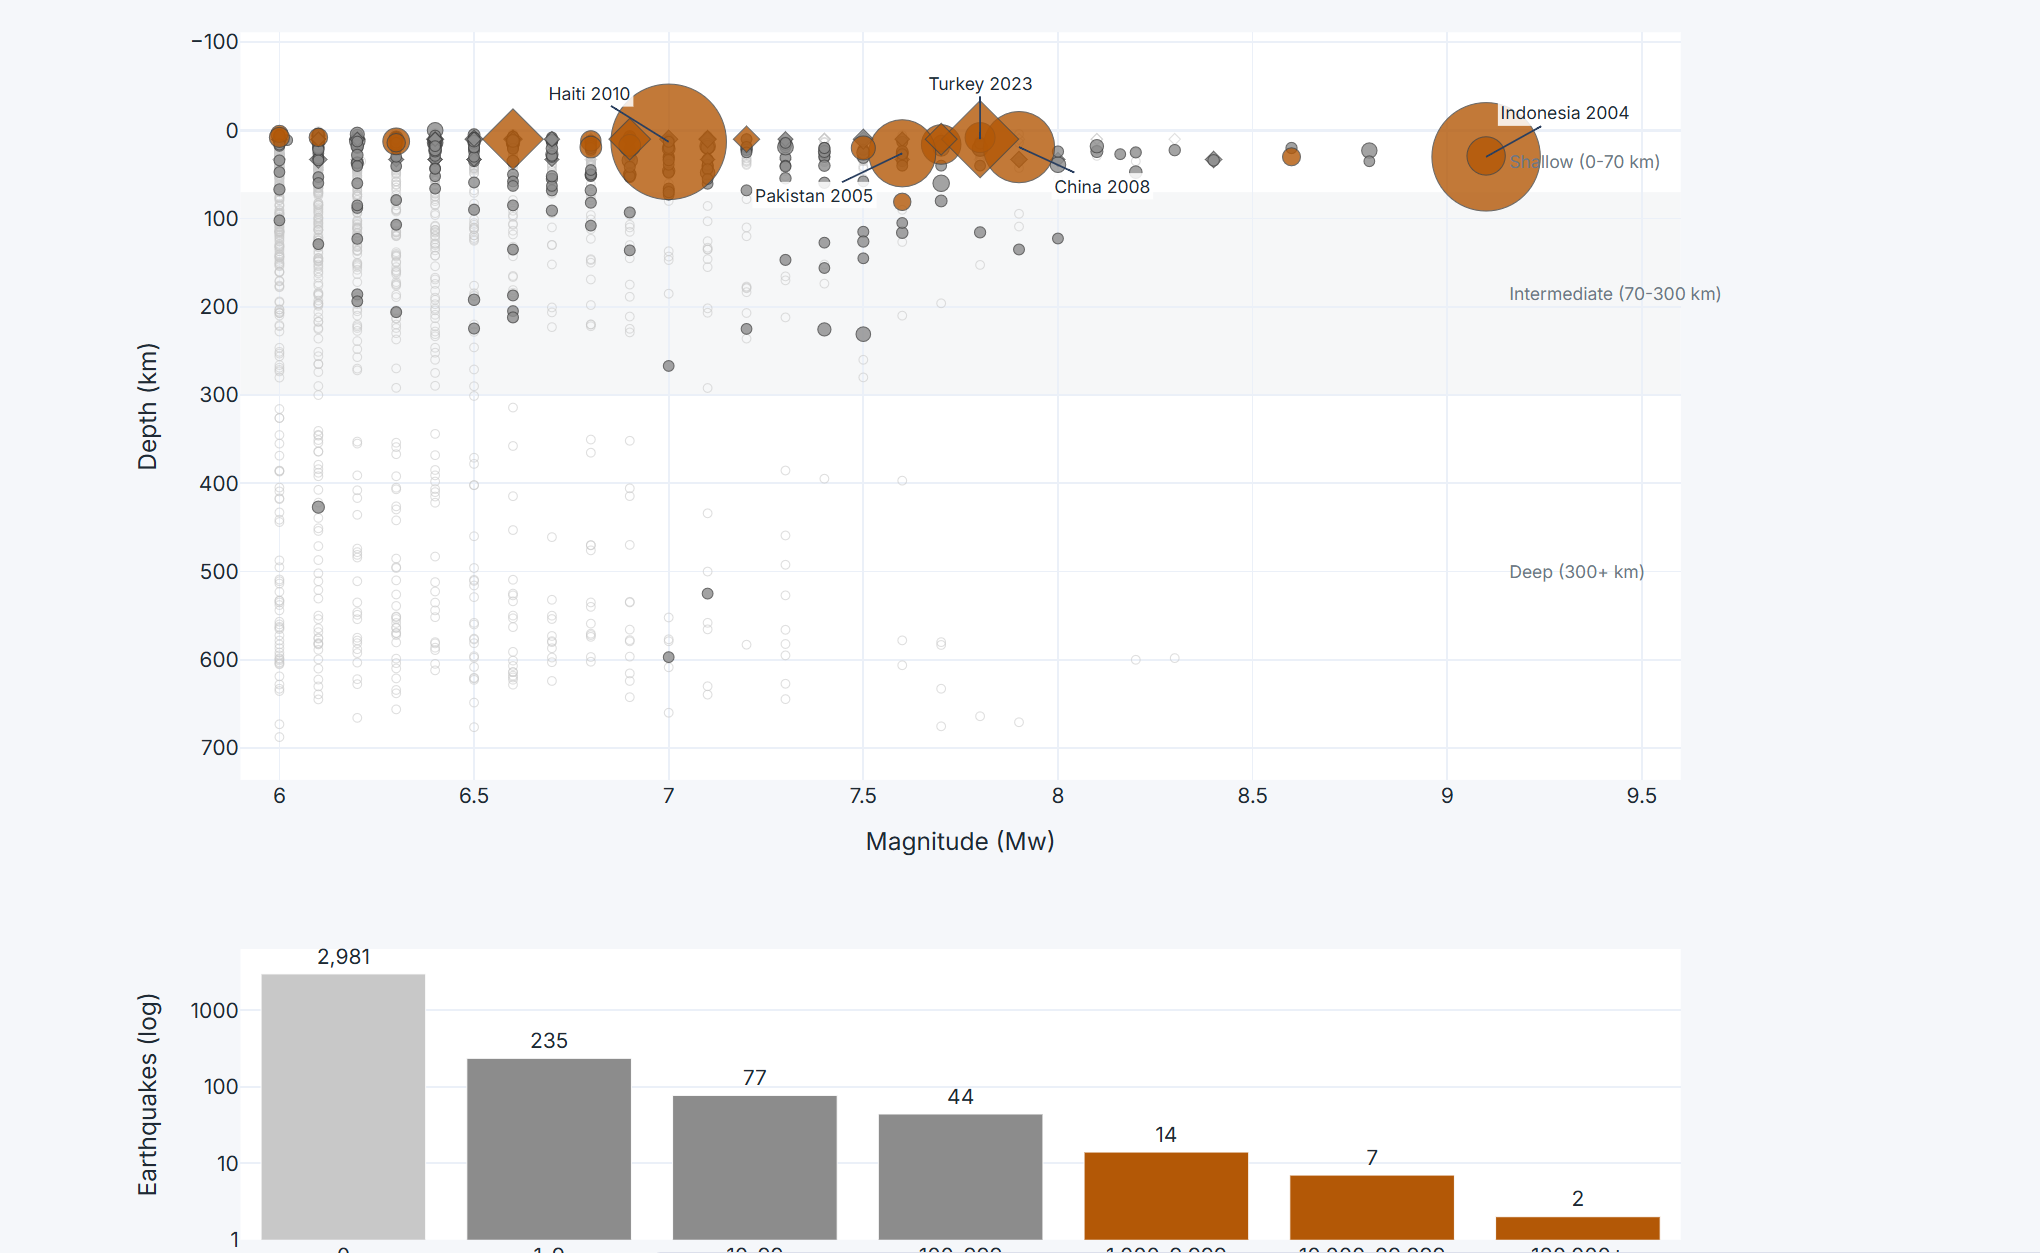

**Analysis:** Magnitude and focal depth are important physical controls on earthquake impact. In this dataset, shallow earthquakes (≤70 km) account for over 99% of onshore earthquake fatalities, while deep earthquakes (>300 km) contribute a negligible fraction.

However, even when magnitude is held within a similar range (for example, Mw 7.0–7.4), reported fatalities vary dramatically - from zero to over 200,000. This substantial variation suggests that magnitude and depth alone cannot explain the human impact of earthquakes. Factors such as population exposure, infrastructure, preparedness, and socioeconomic conditions may also play an important role.

### B. Population Density vs. Regional Context

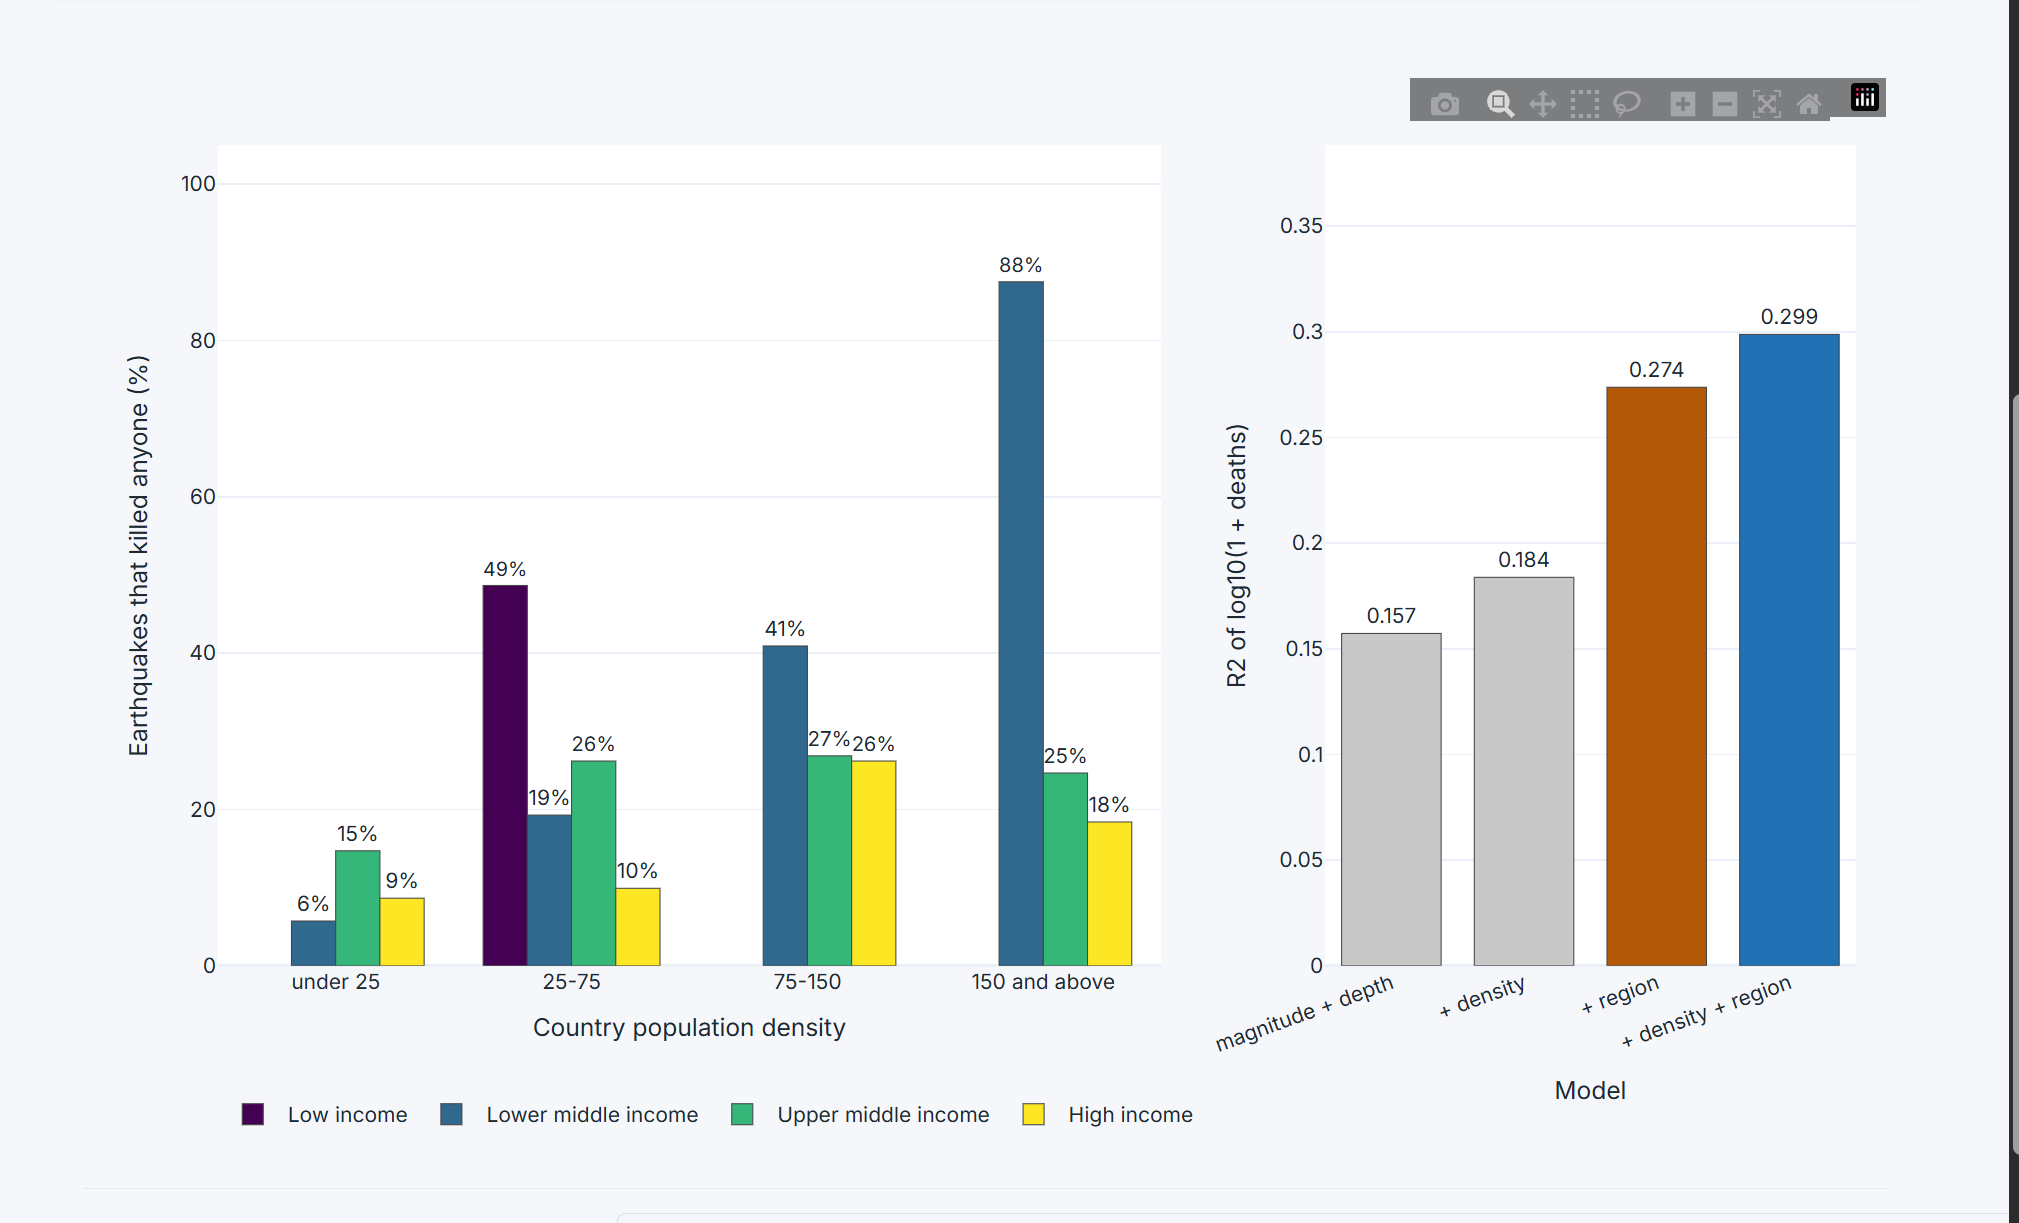

**Analysis:** The left plot shows how the percentage of earthquakes resulting in at least one death varies across country population-density categories and income groups. The differences across these groups suggest that population density alone does not consistently explain earthquake impacts.

A nested OLS regression using $\log_{10}(1+\text{deaths})$ as the target shows that adding country-level population density to the physical model (magnitude and depth) increases $R^2$ from 0.157 to 0.184, a gain of **2.7 percentage points**. This limited improvement may reflect an ecological limitation: national population density does not capture the population actually exposed near an earthquake's epicentre.

In contrast, adding region increases $R^2$ from 0.157 to 0.274, a gain of **11.7 percentage points**. The model including both population density and region achieves the highest $R^2$ of **0.299**. Region may capture broader differences in seismic exposure, construction practices, building-code enforcement, and disaster preparedness that national population density cannot directly represent.

Overall, regional context provides substantially more explanatory information than national population density in these models. However, this is an observational association; the improvement from adding region does not establish that construction practices or building codes are the specific cause.

### C. The Income Shield (GDP per Capita PPP Int.Dollar)

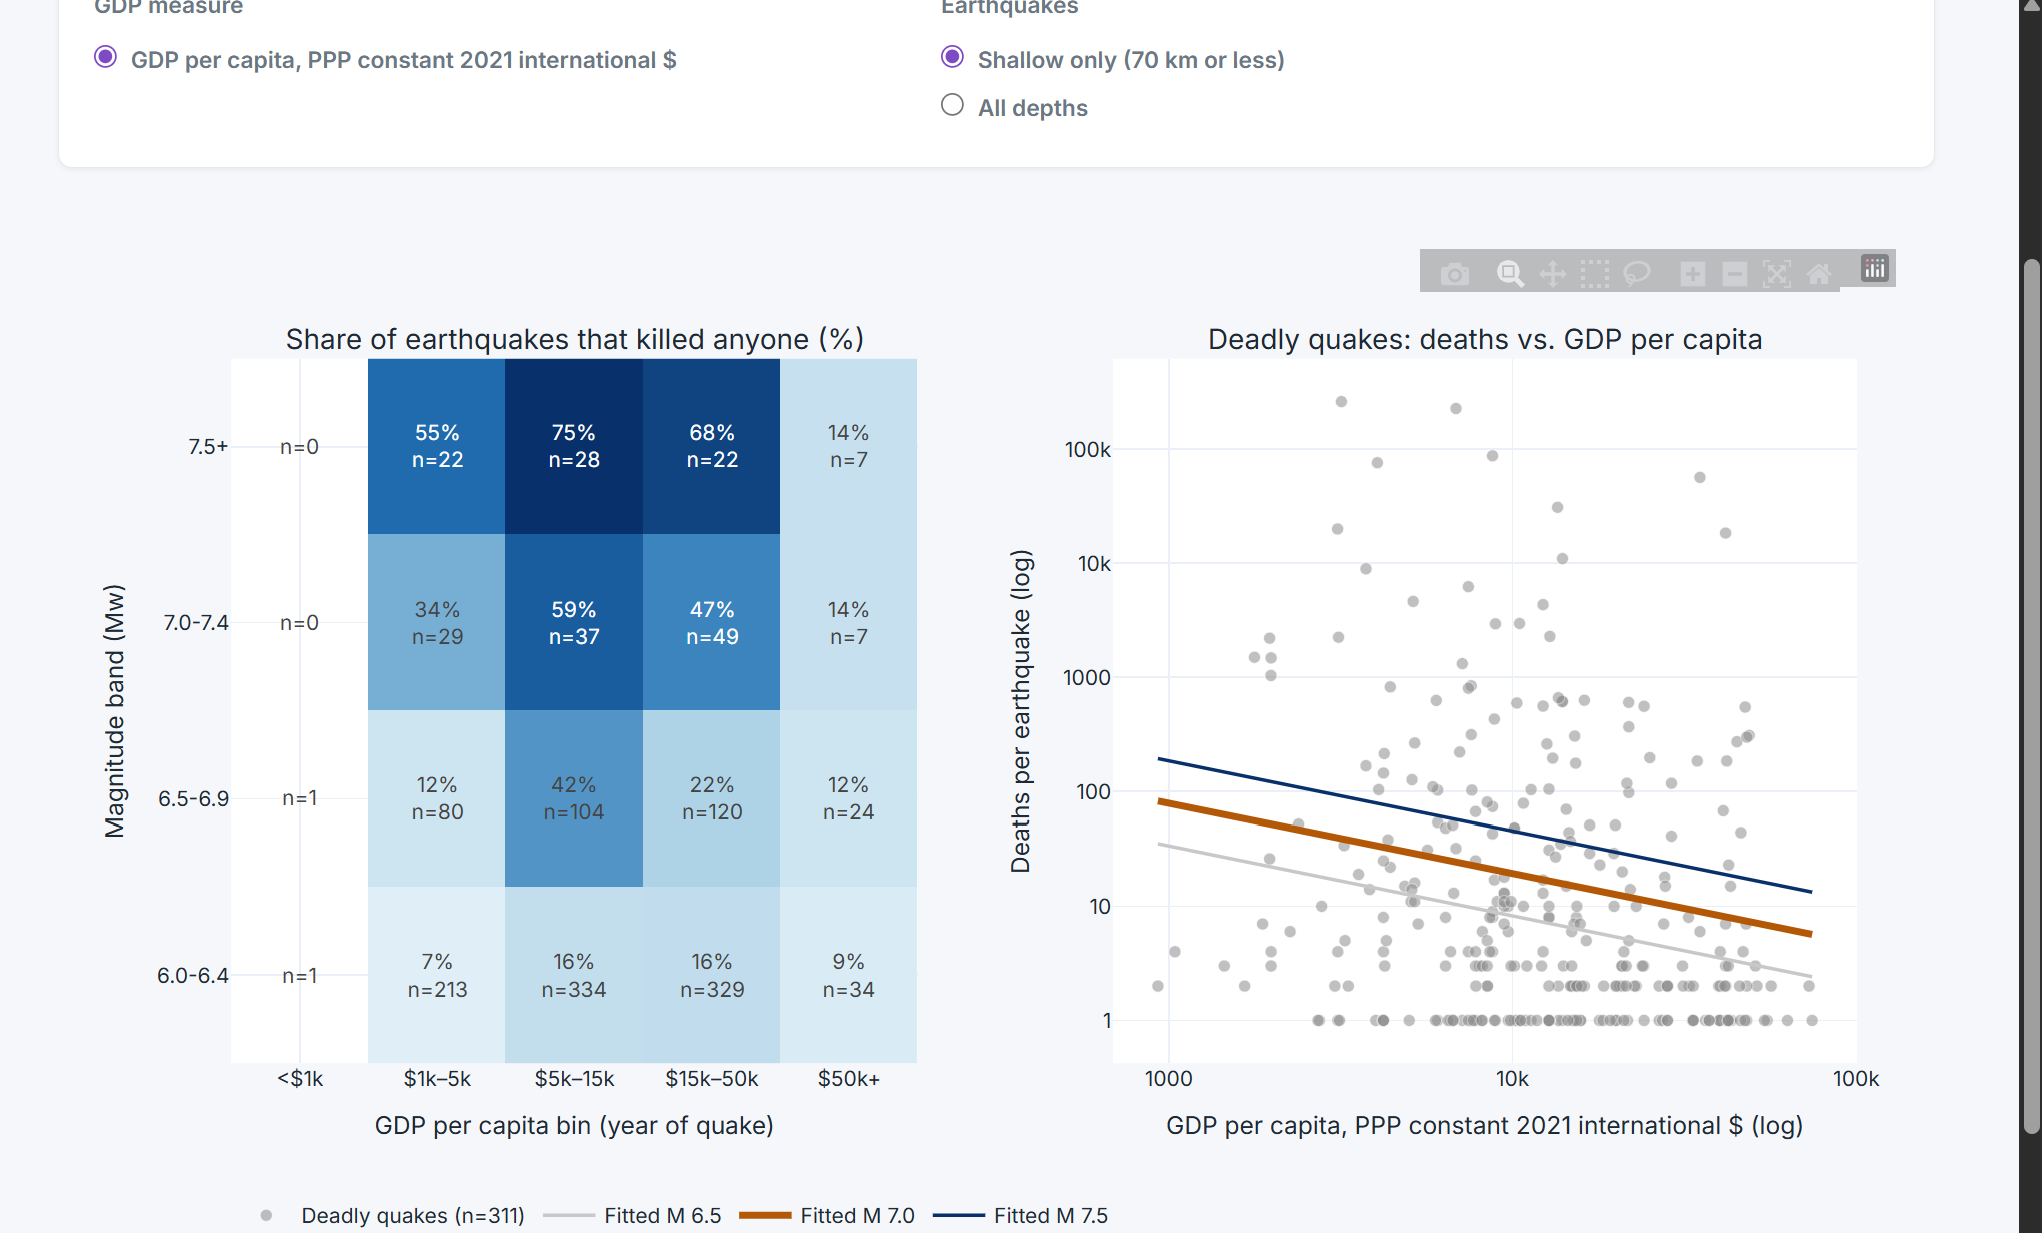


Analysis: Filtering strictly for deadly earthquakes, a clear socio-economic divide emerges. Low and Lower-Middle-income nations suffer an average of over 170 to 770 deaths per deadly earthquake, whereas High-income nations average fewer than 40.

### D. The Predictor & Historical Counterfactuals

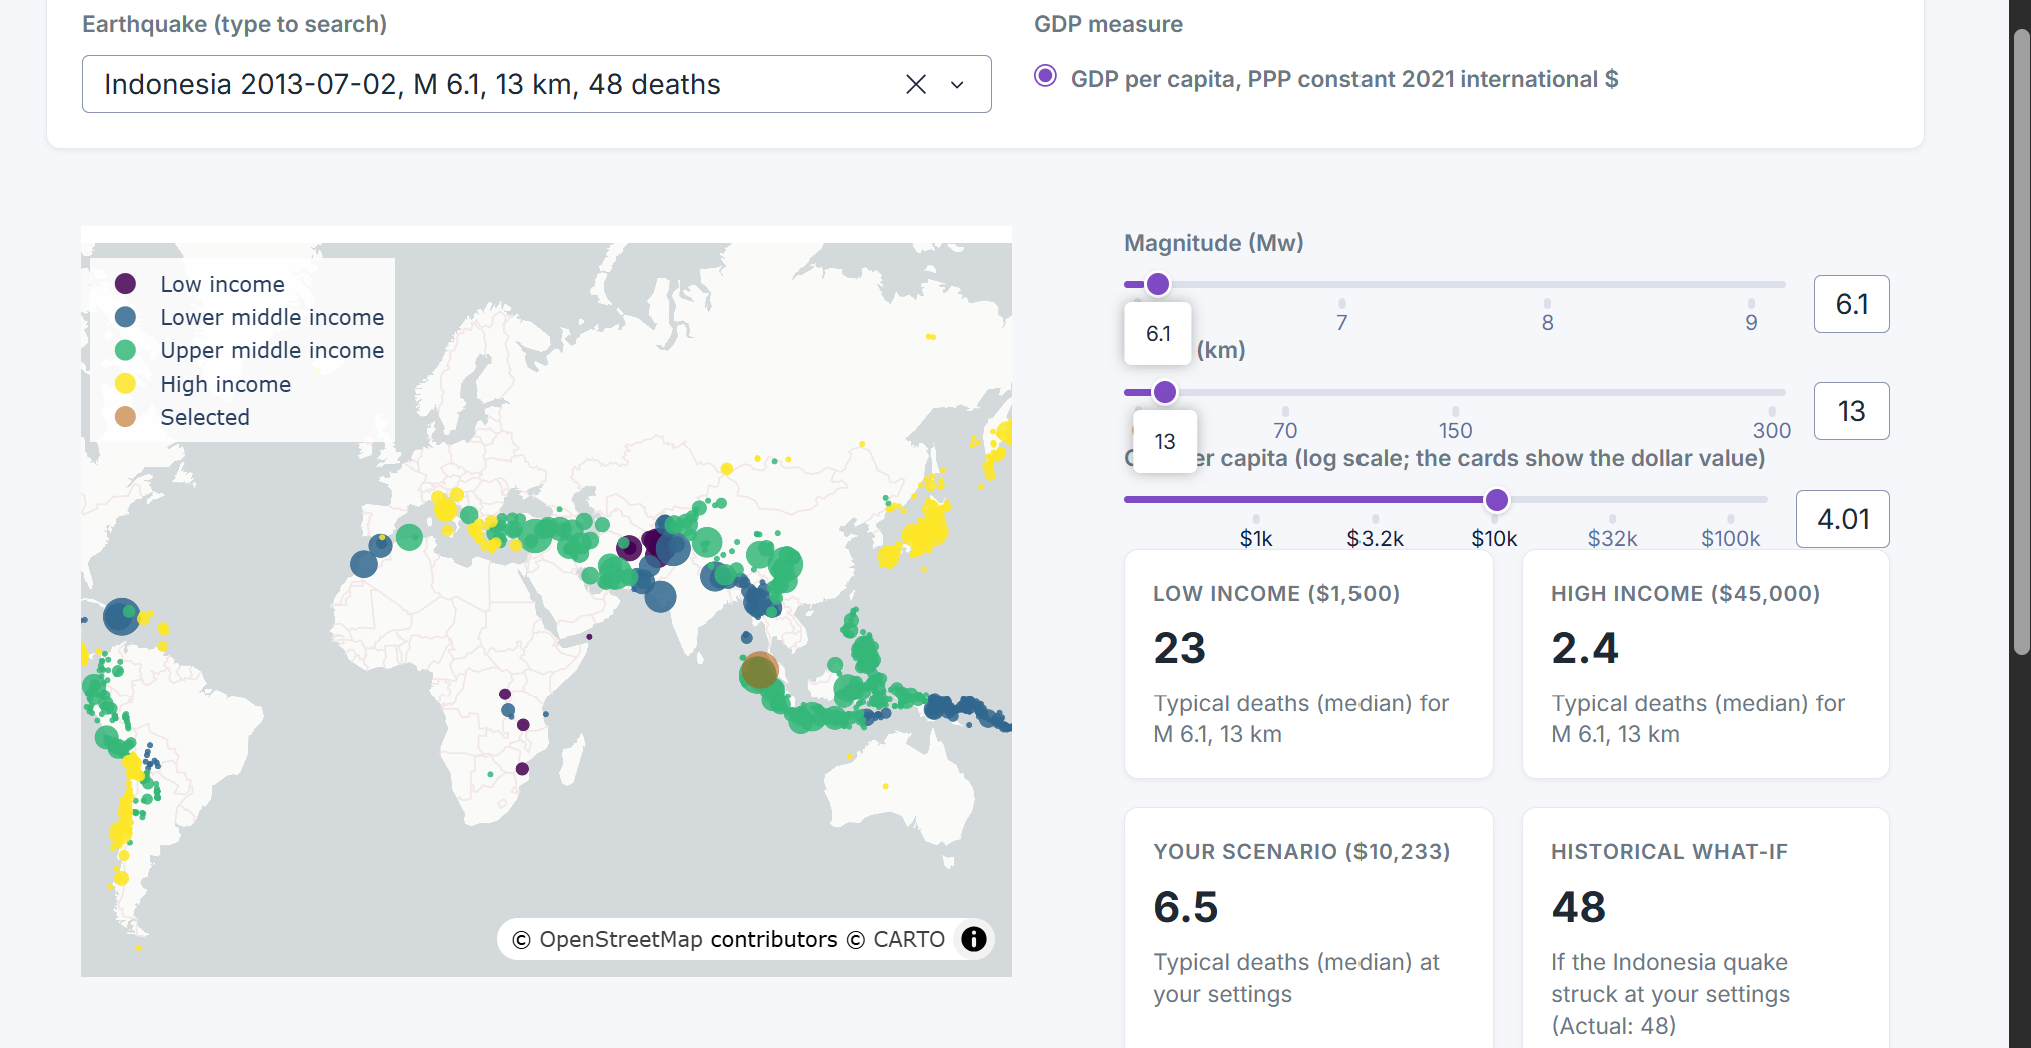

Analysis: To account for the heavy right-skew of disaster mortality (where 80% of quakes kill 0 people), a Two-Part Hurdle Model was applied.
- Part 1 (Logistic): Calculates the probability that an earthquake kills at least one person based on its depth, magnitude, and local GDP.

- Part 2 (OLS + Smearing): If the disaster clears the hurdle, an OLS model predicts the severity of the toll, utilizing Duan's smearing factor to accurately estimate the expected mean. In a simulated counterfactual, an M7.0 shallow quake hitting a $1,500 GDP nation yields nearly 100 expected deaths, whereas the exact same physical event hitting a $45,000 GDP nation yields roughly 10 deaths.

## 7. Conclusion
Does a country's income explain earthquake deaths? **Yes.** After strictly controlling for physical hazard limits (magnitude and depth), economic wealth serves as a massive protective shield.

According to our combined econometric model, every 10x increase in a country's GDP per capita (PPP) results in roughly a **76% reduction in expected fatalities during a deadly event.** 

Wealth effectively buys seismic resilience through stricter building codes, superior emergency response infrastructure, and robust zoning laws.

## 8. Limitations
**Geographical Snapping:** Offshore earthquakes matched to NOAA reports were snapped to the nearest coast within 5 degrees, which may occasionally assign a marine event to an adjacent non-impacted jurisdiction.

**Granularity:** The model utilizes national-average population density and GDP. This obscures extreme wealth inequalities or localized population clusters within large nations (e.g., rural vs. urban China or the US).

**Missing Variables:** The model accounts for ~30% of the variance in mortality. The remaining 70% is driven by hyper-local factors omitted from macro-datasets, such as the exact time of day of the rupture (asleep vs. awake/outdoors), soil liquefaction, and secondary hazards like tsunamis.

## 9. Attributions & Contributions
Technical Attributions
- Libraries: pandas, numpy, pyarrow (Parquet data formatting), sqlite3 (parameterized database execution), requests, BeautifulSoup4 (HTML parsing), scikit-learn (DBSCAN Spatiotemporal clustering), plotly, dash, dash-bootstrap-components, flask.

- AI Tool Disclosure: LLMs (Gemini / ChatGPT) were utilized collaboratively to debug Dash callback pathing limitations, refining complex regular expressions for unstructured Wikipedia string extraction, and implementing the final dashboard.

Team Contributions

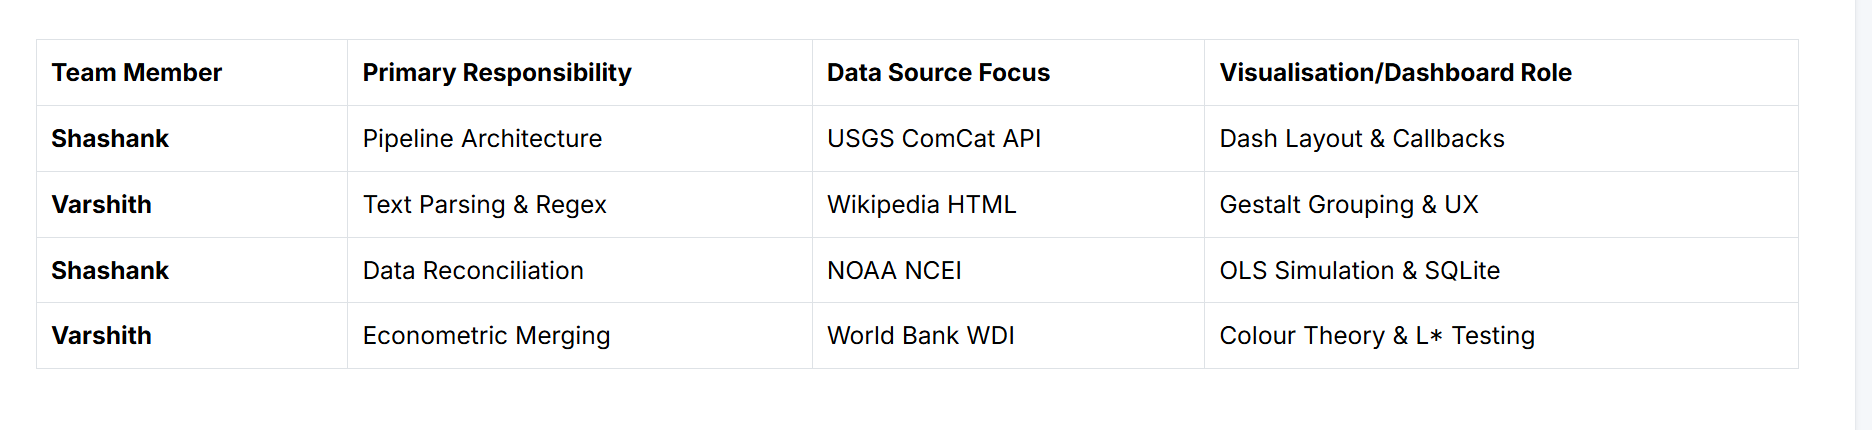

### 10. **Note:** Dashboard Execution Instructions

To view and interact with the analytical dashboard locally, open a terminal at the root of the project directory and execute the following command: 

```python notebooks/dashboard.py```

Once the Dash server initializes, copy the provided localhost URL (typically [http://127.0.0.1:8050/](http://127.0.0.1:8050/)) and paste it into any standard web browser.